# 02 · Parte 1: HMM y clasificador del día siguiente (implementación propia)

Todo el modelado está en `src/aire/hmm.py`, `src/aire/classifier.py` y `src/aire/forecast.py` (NumPy). scikit-learn solo se usa en `tests/` para verificar resultados.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "font.size": 10})
AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
FIG = ROOT / "reports" / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
from aire import config as C
from aire.forecast import log_wide, fit_hmm, build_features, evaluate_split
lw = log_wide(); hmm = fit_hmm(lw, end=C.TRAIN_END)
print('Medias por estado (µg/m³):', np.exp(hmm.mu).round(1)); print('Matriz de transición:'); print(hmm.A.round(3))
print('Duración esperada (días):', (1/(1-np.diag(hmm.A))).round(1)); print('Iteraciones EM:', len(hmm.history))

Medias por estado (µg/m³): [11.5 17.8 30. ]
Matriz de transición:
[[0.94  0.06  0.   ]
 [0.045 0.924 0.031]
 [0.    0.057 0.943]]
Duración esperada (días): [16.7 13.1 17.6]
Iteraciones EM: 19


## Convergencia de Baum-Welch (la log-verosimilitud no decrece)

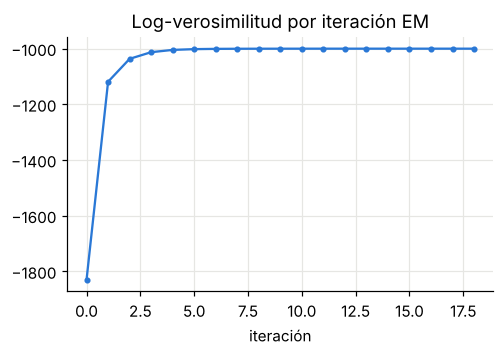

In [2]:
plt.figure(figsize=(5,3)); plt.plot(hmm.history, color=AZUL, marker='o', ms=3); plt.title('Log-verosimilitud por iteración EM'); plt.xlabel('iteración'); plt.show()

## Estados latentes filtrados en una estación (Itagüí – Casa de Justicia)

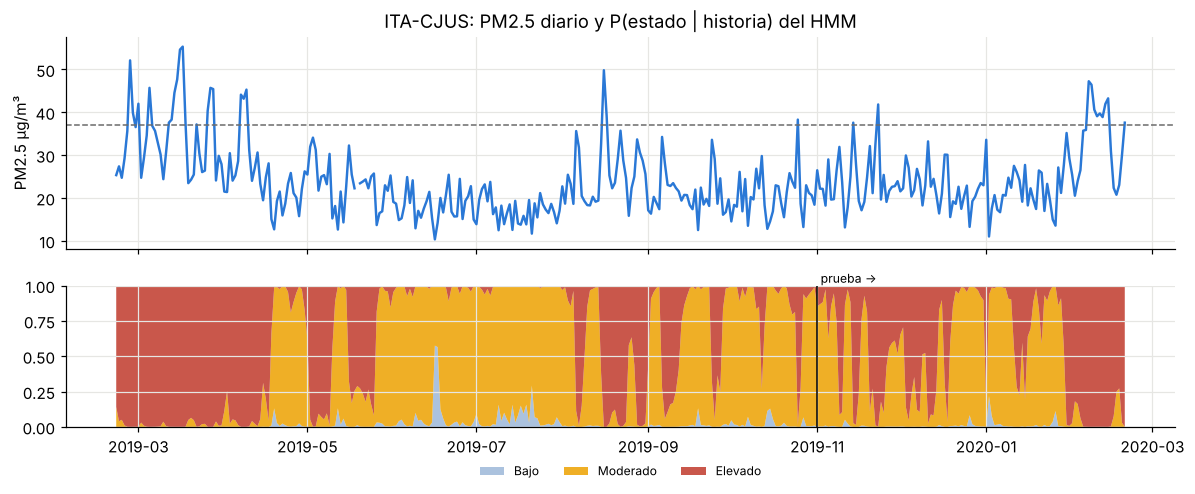

In [3]:
f = build_features(lw, hmm); s = f[f.codigo == 28].set_index('fecha')
fig, ax = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True, gridspec_kw={'height_ratios': [3, 2]})
ax[0].plot(s.index, s['pm25_t'], color=AZUL, lw=1.6); ax[0].axhline(37, ls='--', color='#6b6b6b', lw=1)
ax[0].set_ylabel('PM2.5 µg/m³'); ax[0].set_title('ITA-CJUS: PM2.5 diario y P(estado | historia) del HMM')
ax[1].stackplot(s.index, s['p_normal'], s['p_alerta'], s['p_critico'], colors=['#9db8d9', AMARILLO, '#c0392b'],
                labels=C.HMM_STATES, alpha=.85); ax[1].set_ylim(0, 1); ax[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=8, frameon=False)
ax[1].axvline(pd.Timestamp(C.TEST_START), color='k', lw=1); ax[1].text(pd.Timestamp(C.TEST_START), 1.02, ' prueba →', fontsize=8)
plt.tight_layout(); plt.savefig(FIG / 'fig2_hmm_estados.png', bbox_inches='tight'); plt.show()

## Evaluación: periodo de prueba (nov-2019 → feb-2020) frente a líneas base

In [4]:
r = json.loads((ROOT / 'reports' / 'metricas_parte1.json').read_text(encoding='utf-8'))
rows = [{'modelo': k, 'acc': v['accuracy'], 'f1_macro': v['macro_f1'], 'bal_acc': v['balanced_accuracy'],
         'recall_exced': v['excedencia_norma']['recall'], 'f1_exced': v['excedencia_norma']['f1'],
         'log_loss': v.get('log_loss')} for k, v in r['clasificacion_dia_siguiente'].items()]
tab = pd.DataFrame(rows).set_index('modelo'); tab.round(3)

,acc,f1_macro,bal_acc,recall_exced,f1_exced,log_loss
modelo,,,,,,
Regresión logística + estados HMM,0.768,0.574,0.737,0.838,0.396,0.522
Regresión logística sin HMM (ablación),0.783,0.583,0.732,0.838,0.413,0.530
Naive Bayes gaussiano + estados HMM,0.641,0.484,0.736,0.912,0.280,2.093
HMM solo (pronóstico a un paso),0.834,0.449,0.454,0.000,0.000,0.413
Línea base: persistencia,0.831,0.594,0.593,0.441,0.448,NaN
Línea base: climatología (frecuencias),0.849,0.306,0.333,0.000,0.000,0.529


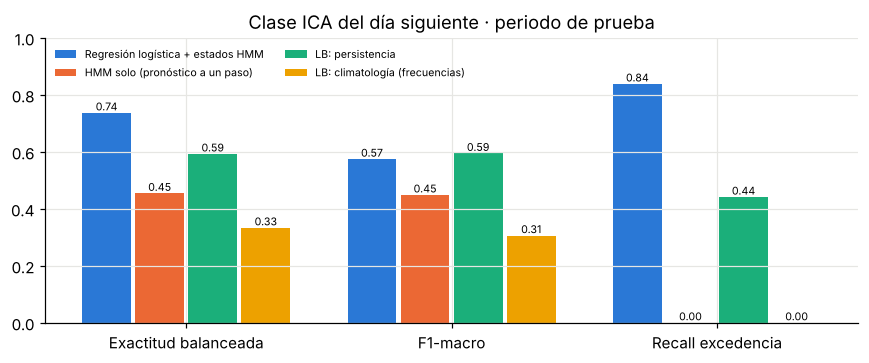

In [5]:
sel = ['Regresión logística + estados HMM', 'HMM solo (pronóstico a un paso)', 'Línea base: persistencia', 'Línea base: climatología (frecuencias)']
mets = ['bal_acc', 'f1_macro', 'recall_exced']; names = ['Exactitud balanceada', 'F1-macro', 'Recall excedencia']
x = np.arange(len(mets)); wd = 0.2
fig, ax = plt.subplots(figsize=(8, 3.4))
for i, (mname, col) in enumerate(zip(sel, [AZUL, NARANJA, AQUA, AMARILLO])):
    vals = tab.loc[mname, mets].values.astype(float)
    b = ax.bar(x + (i - 1.5) * wd, vals, wd * .92, color=col, label=mname.replace('Línea base: ', 'LB: '))
    ax.bar_label(b, fmt='%.2f', fontsize=7)
ax.set_xticks(x, names); ax.set_ylim(0, 1); ax.legend(fontsize=7, ncol=2, frameon=False, loc='upper left')
ax.set_title('Clase ICA del día siguiente · periodo de prueba'); plt.tight_layout()
plt.savefig(FIG / 'fig3_comparacion_modelos.png', bbox_inches='tight'); plt.show()

## Validación temporal con ventana creciente (6 meses) y selección de hiperparámetros

In [6]:
cv = pd.read_csv(ROOT / 'reports' / 'validacion_temporal.csv')
display(cv.pivot(index='mes_prueba', columns='modelo', values='macro_f1').round(3))
pd.DataFrame(r['seleccion_hiperparametros']['tabla_cv_entrenamiento']).round(4)

modelo,HMM solo (pronóstico a un paso),Línea base: climatología (frecuencias),Línea base: persistencia,Naive Bayes gaussiano + estados HMM,Regresión logística + estados HMM,Regresión logística sin HMM (ablación)
mes_prueba,,,,,,
2019-09,0.427,0.299,0.442,0.415,0.405,0.402
2019-10,0.459,0.290,0.445,0.479,0.478,0.472
2019-11,0.487,0.303,0.502,0.520,0.567,0.551
2019-12,0.451,0.310,0.509,0.489,0.552,0.540
2020-01,0.592,0.454,0.669,0.544,0.668,0.665
2020-02,0.310,0.310,0.497,0.323,0.478,0.514


,class_weight,l2,macro_f1_cv,log_loss_cv
0,sqrt,0.001,0.5860,0.4414
1,sqrt,0.010,0.5804,0.4316
2,balanced,0.001,0.5796,0.5198
3,NaN,0.010,0.5738,0.4099
4,balanced,0.010,0.5603,0.5361
5,sqrt,0.100,0.5566,0.4822
6,NaN,0.100,0.5547,0.4338
7,NaN,0.001,0.5534,0.4348
8,balanced,0.100,0.5243,0.6447


## HMM: número de estados (log-verosimilitud por observación en prueba)
Más estados mejoran la verosimilitud; se eligen **3** por interpretabilidad (bajo/moderado/elevado, análogos al normal/alerta/episodio del enunciado).

In [7]:
r['hmm']['loglik_prueba_por_obs']

{'HMM-1': -0.4717, 'HMM-2': -0.2499, 'HMM-3': -0.1658, 'HMM-4': -0.1244}

## Matriz de confusión del modelo principal

In [8]:
cm = np.array(r['clasificacion_dia_siguiente']['Regresión logística + estados HMM']['confusion_matrix'])
pd.DataFrame(cm, index=[f'real {c}' for c in C.CLASSES], columns=[f'pred {c}' for c in C.CLASSES])

,pred Buena,pred Aceptable,pred Dañina
real Buena,157,109,5
real Aceptable,236,1505,158
real Dañina,0,11,57


**Lectura.** La regresión logística (con pesos de clase √) detecta la mayoría de los días que superan la norma (recall ≈ 0.84 frente a 0.44 de la persistencia) a costa de falsas alarmas, y mejora la exactitud balanceada; la persistencia conserva un F1-macro algo mayor en esta partición, pero no en la validación temporal. El HMM solo da las probabilidades mejor calibradas (menor log-loss). La ablación muestra que las probabilidades del HMM **no** mejoran de forma apreciable al clasificador: su aporte principal es el pronóstico probabilístico y la interpretación del régimen.